# Step 4 · Evaluate all models and plot (AD and MCI)

Scores every model **with identical code** from the common prediction files and writes the manuscript
tables and figures. A model that has not been run yet
is skipped and reported; all tables and figures adapt to the models present. Re-run this notebook after
adding a model; nothing is refitted here.

| Input | Output |
|---|---|
| `results/{AD,MCI}/inputs/` (step 1) | `results/{AD,MCI}/evaluation/` — Table 1 (cohort characteristics), Table S1 (participant flow), metrics with 95% CIs, Table 2, Table 3, calibration, risk groups |
| `results/{AD,MCI}/<model>/predictions.csv`, `feature_importance.csv` (steps 2–3) | `plots/{AD,MCI}/Figure1–3`, `FigureS1–S6` |

| Main figure / table | Content |
|---|---|
| Figure1_participant_flow | Participant flow from the source data to the month-48 cohort |
| Figure2_performance_by_history | IBS and AUC-60 by visit history (first visit = init, latest 1 = last, all prior = aggregated); reference lines: chance and the no-covariate model |
| Figure3_risk_groups | Kaplan–Meier by predicted-risk group with numbers at risk, per model |
| Table1 / Table2 / Table3 | Cohort characteristics; performance by model and history (with n, events); paired differences (incl. % change in IBS) |

| Supplementary | Content |
|---|---|
| FigureS1_three_vs_one_visits | Latest 3 minus latest 1 visit, per model (primary contrast) |
| FigureS2_model_comparison | Each model minus Landmark Cox (latest 3, the reference at 0) |
| FigureS3_auc_over_time | AUC over 24–60 months after the landmark |
| FigureS4_calibration | Calibration at 60 months, per model |
| FigureS5_risk_distribution | Predicted 60-month risk by risk group |
| FigureS6_feature_importance | Permutation importance (latest 3 visits, held-out NACC folds) |
| TableS1_participant_flow | Counts behind Figure 1 |

Primary metric: integrated Brier score over 24–60 months after month 48 (lower is better).

In [ ]:
import os, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(os.environ.get("SURVIVAL_PROJECT_DIR", "/Users/yihan/Documents/Github/survival_Anlysis_Clustering"))
if str(PROJECT_DIR / "code") not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR / "code"))
import landmark_common as lc
import landmark_evaluation as ev

RUN_MODE = lc.run_mode()  # "standard"; checks/smoke_test.py sets "smoke"
MODELS = lc.ALL_MODELS  # Landmark Cox, DeepSurv, Dynamic-DeepHit
ENDPOINTS = lc.ENDPOINTS
print(f"mode={RUN_MODE}; candidate models={MODELS}")

mode=standard; candidate models=['Cox_ridge', 'DeepSurv', 'DynamicDeepHit']


## AD: CU/MCI → dementia

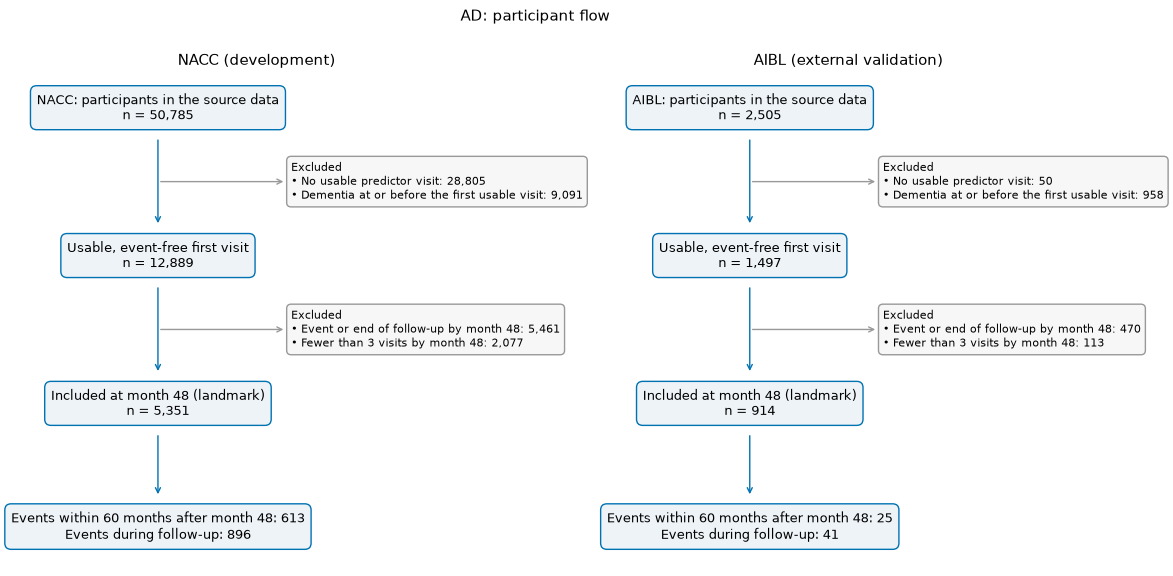

AD: scoring Cox_ridge / baseline_visit
AD: scoring Cox_ridge / 1_visit
AD: scoring Cox_ridge / 2_visits
AD: scoring Cox_ridge / 3_visits
AD: scoring Cox_ridge / all_visits
AD: scoring Cox_ridge / basic_only
AD: scoring DeepSurv / baseline_visit
AD: scoring DeepSurv / 1_visit
AD: scoring DeepSurv / 2_visits
AD: scoring DeepSurv / 3_visits
AD: scoring DeepSurv / all_visits
AD: scoring DynamicDeepHit / baseline_visit
AD: scoring DynamicDeepHit / 1_visit
AD: scoring DynamicDeepHit / 2_visits
AD: scoring DynamicDeepHit / 3_visits
AD: scoring DynamicDeepHit / all_visits
AD NACC_internal: bootstrap 50/200
AD NACC_internal: bootstrap 100/200
AD NACC_internal: bootstrap 150/200
AD NACC_internal: bootstrap 200/200
AD AIBL_external: bootstrap 50/200
AD AIBL_external: bootstrap 100/200
AD AIBL_external: bootstrap 150/200
AD AIBL_external: bootstrap 200/200


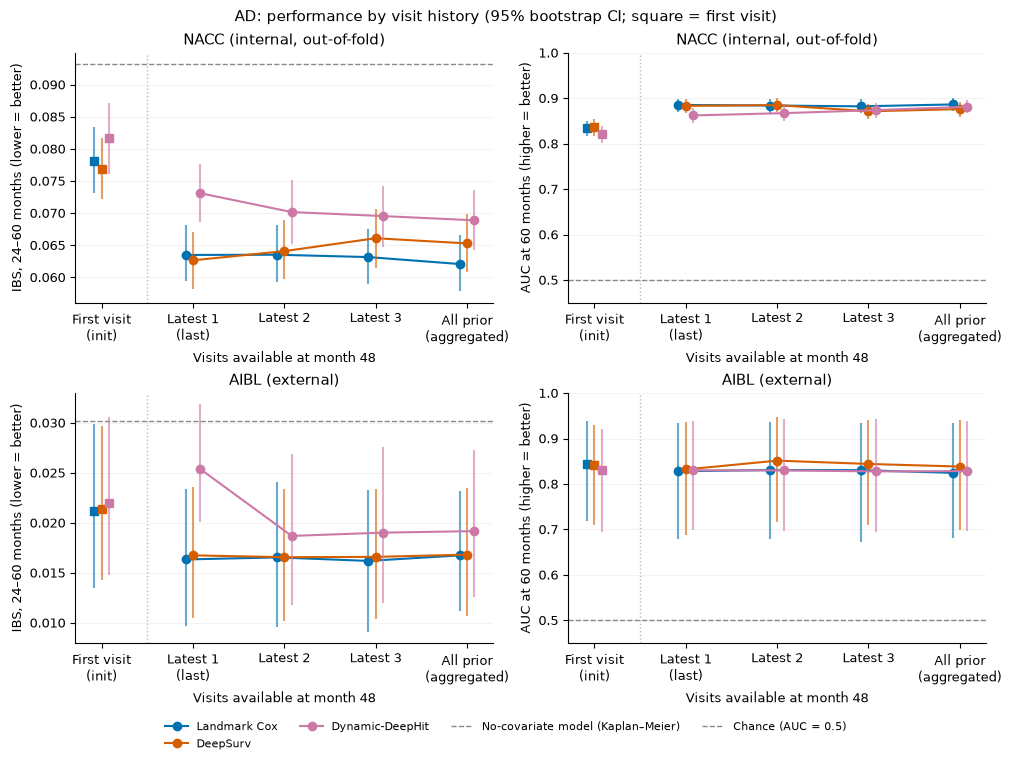

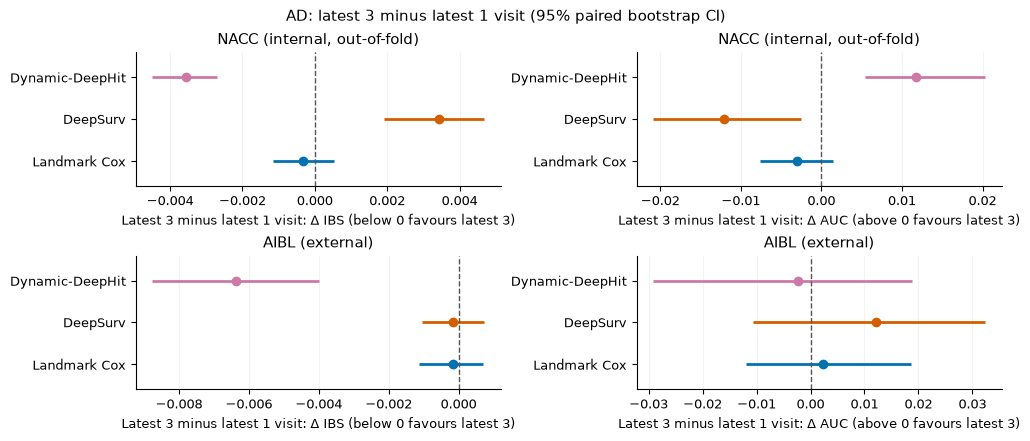

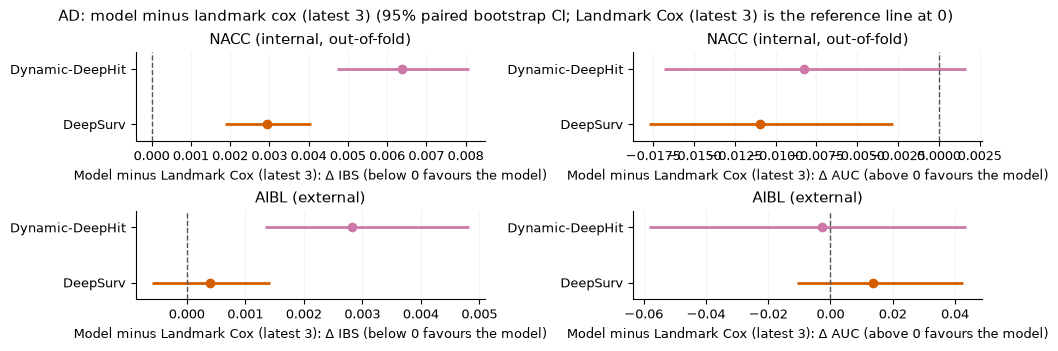

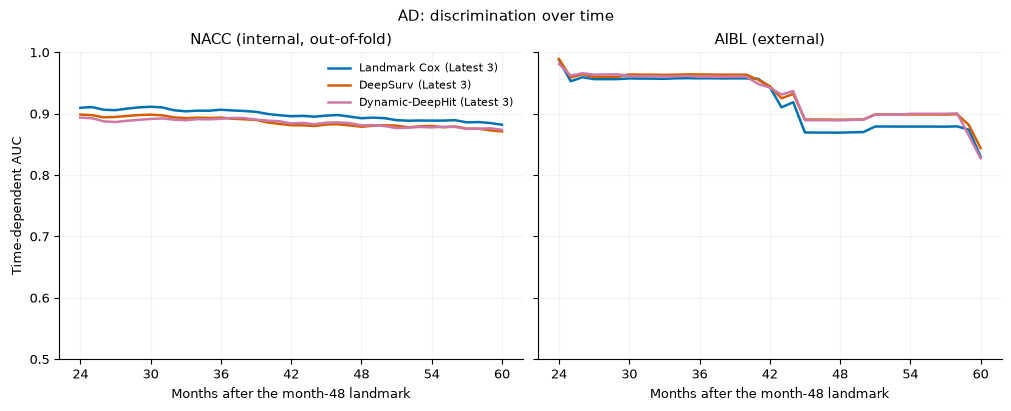

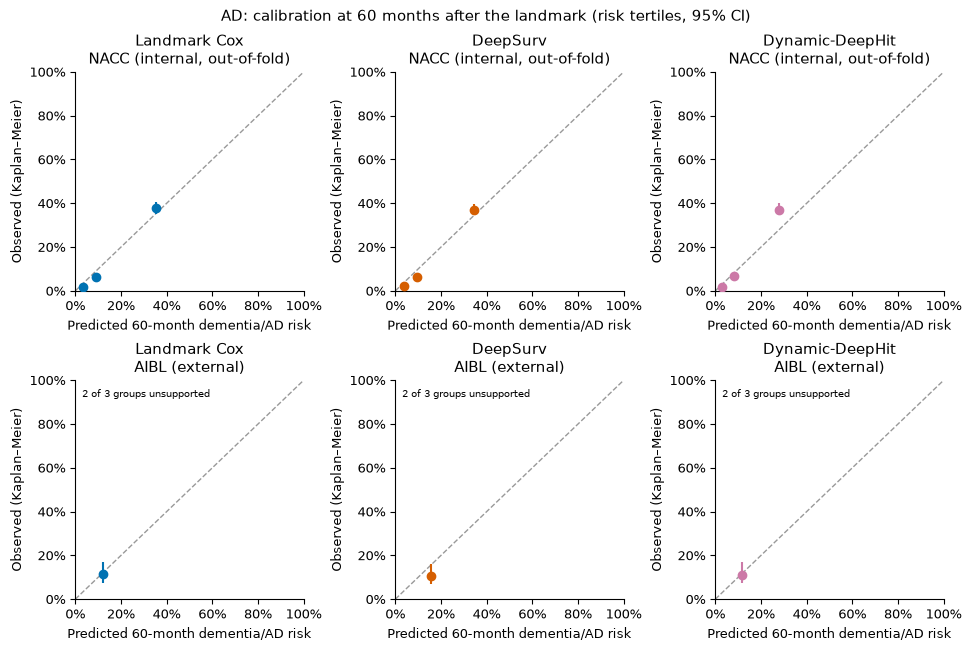

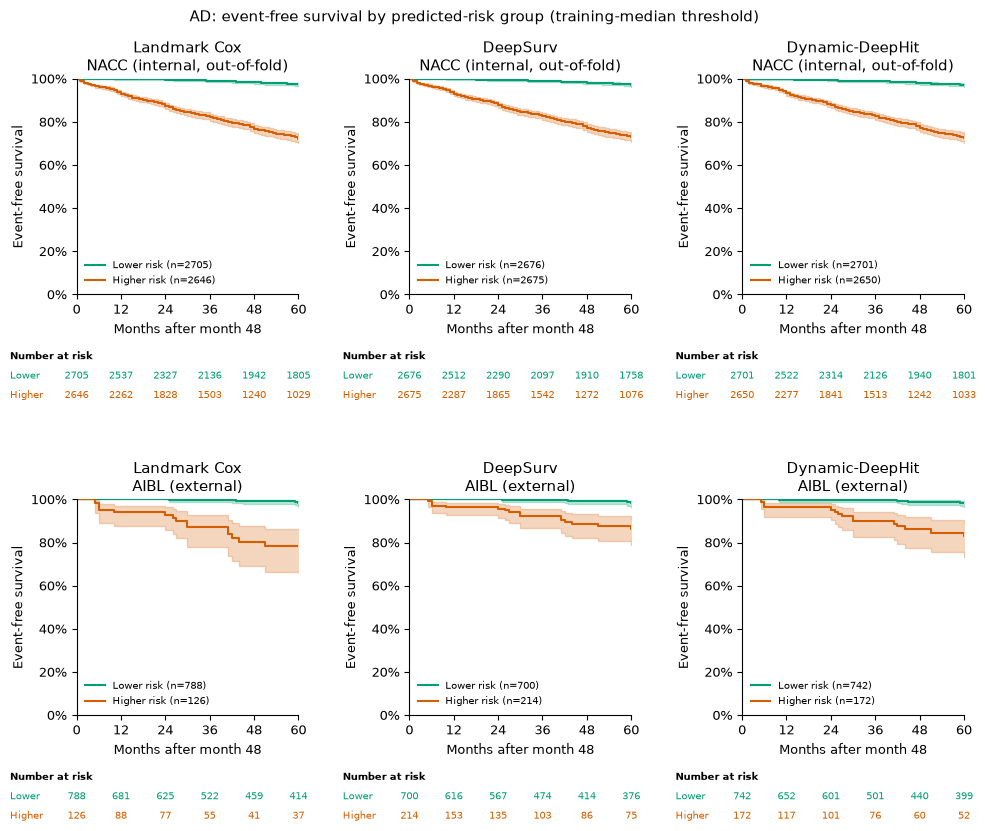

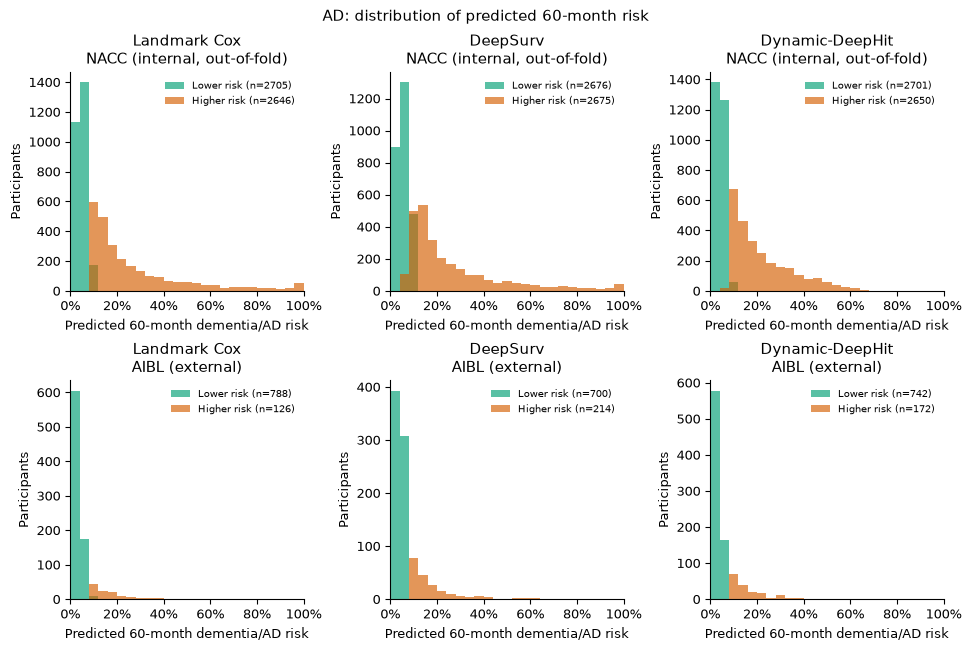

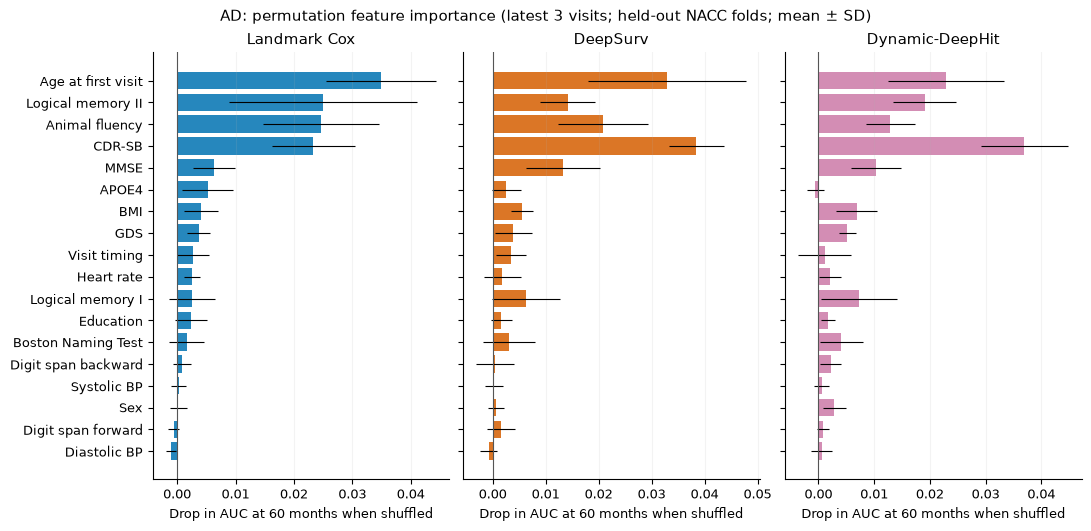

Models evaluated: ['Cox_ridge', 'DeepSurv', 'DynamicDeepHit']


,NACC (development),AIBL (external validation)
Characteristic,,
"Participants, n",5351,914
"Events within 24 months after month 48, n (%)",311 (5.8%),8 (0.9%)
"Events within 36 months after month 48, n (%)",421 (7.9%),13 (1.4%)
"Events within 60 months after month 48, n (%)",613 (11.5%),25 (2.7%)
"Events during follow-up (to 120 months), n (%)",896 (16.7%),41 (4.5%)
"Median follow-up after month 48, months (reverse Kaplan–Meier)",76.0,60.0
"Age at first visit, years, mean (SD)",72.5 (9.2),70.5 (6.6)
"Female, n (%)",3421 (63.9%),499 (54.6%)
"Education, years, mean (SD)",15.8 (3.0),12.6 (3.2)


,NACC,AIBL
Participants,,
source_participants,50785,2505
no_usable_visit,28805,50
prevalent,9091,958
usable_baseline,12889,1497
event_or_censored_by_48,5461,470
fewer_than_3_visits,2077,113
included,5351,914
events_by_24m,311,8
events_by_36m,421,13


metric                                          n  events_by_60m  \
cohort        model          history                               
AIBL_external Cox_ridge      baseline_visit   914             25   
                             1_visit          914             25   
                             2_visits         914             25   
                             3_visits         914             25   
                             all_visits       914             25   
                             basic_only       914             25   
              DeepSurv       baseline_visit   914             25   
                             1_visit          914             25   
                             2_visits         914             25   
                             3_visits         914             25   
                             all_visits       914             25   
              DynamicDeepHit baseline_visit   914             25   
                             1_visit          914             25   
                             2_visits         914             25   
                             3_visits         914             25   
                             all_visits       914             25   
              Null_KM        no_covariates    914             25   
NACC_internal Cox_ridge      baseline_visit  5351            613   
                             1_visit         5351            613   
                             2_visits        5351            613   
                             3_visits        5351            613   
                             all_visits      5351            613   
                             basic_only      5351            613   
              DeepSurv       baseline_visit  5351            613   
                             1_visit         5351            613   
                             2_visits        5351            613   
                             3_visits        5351            613   
                             all_visits      5351            613   
              DynamicDeepHit baseline_visit  5351            613   
                             1_visit         5351            613   
                             2_visits        5351            613   
                             3_visits        5351            613   
                             all_visits      5351            613   
              Null_KM        no_covariates   5351            613   

metric                                                    IBS_24_60  \
cohort        model          history                                  
AIBL_external Cox_ridge      baseline_visit  0.021 (0.014 to 0.030)   
                             1_visit         0.016 (0.010 to 0.023)   
                             2_visits        0.017 (0.010 to 0.024)   
                             3_visits        0.016 (0.009 to 0.023)   
                             all_visits      0.017 (0.011 to 0.023)   
                             basic_only      0.028 (0.021 to 0.036)   
              DeepSurv       baseline_visit  0.021 (0.014 to 0.030)   
                             1_visit         0.017 (0.010 to 0.024)   
                             2_visits        0.017 (0.010 to 0.023)   
                             3_visits        0.017 (0.010 to 0.023)   
                             all_visits      0.017 (0.011 to 0.023)   
              DynamicDeepHit baseline_visit  0.022 (0.015 to 0.031)   
                             1_visit         0.025 (0.020 to 0.032)   
                             2_visits        0.019 (0.012 to 0.027)   
                             3_visits        0.019 (0.012 to 0.028)   
                             all_visits      0.019 (0.013 to 0.027)   
              Null_KM        no_covariates   0.030 (0.023 to 0.039)   
NACC_internal Cox_ridge      baseline_visit  0.078 (0.073 to 0.083)   
                             1_visit         0.063 (0.059 to 0.068)   
                             2_visits        0.064 (0.059 to

In [2]:
ad = ev.run("AD", RUN_MODE, MODELS)
print("Models evaluated:", ad.models)
display(ad.table1)   # Table 1: landmark cohort characteristics
display(ad.flow)     # Table S1: participant flow
display(ad.table2)   # Table 2: performance by model and visit history

In [3]:
display(ad.table3)

metric                                                                                                 IBS_24_60  \
cohort        contrast                                  model          history                                     
AIBL_external history minus latest 1 visit (same model) Cox_ridge      baseline_visit     0.005 (0.003 to 0.008)   
                                                                       2_visits          0.000 (-0.000 to 0.001)   
                                                                       3_visits         -0.000 (-0.001 to 0.001)   
                                                                       all_visits        0.000 (-0.001 to 0.002)   
                                                        DeepSurv       baseline_visit     0.005 (0.002 to 0.008)   
                                                                       2_visits         -0.000 (-0.001 to 0.000)   
                                                                       3_visits         -0.000 (-0.001 to 0.001)   
                                                                       all_visits        0.000 (-0.001 to 0.001)   
                                                        DynamicDeepHit baseline_visit  -0.003 (-0.006 to -0.001)   
                                                                       2_visits        -0.007 (-0.009 to -0.004)   
                                                                       3_visits        -0.006 (-0.009 to -0.004)   
                                                                       all_visits      -0.006 (-0.008 to -0.004)   
              model minus Landmark Cox (latest 3)       DeepSurv       3_visits          0.000 (-0.001 to 0.001)   
                                                        DynamicDeepHit 3_visits           0.003 (0.001 to 0.005)   
NACC_internal history minus latest 1 visit (same model) Cox_ridge      baseline_visit     0.015 (0.012 to 0.017)   
                                                                       2_visits          0.000 (-0.001 to 0.001)   
                                                                       3_visits         -0.000 (-0.001 to 0.001)   
                                                                       all_visits      -0.001 (-0.002 to -0.000)   
                                                        DeepSurv       baseline_visit     0.014 (0.012 to 0.016)   
                                                                       2_visits           0.001 (0.000 to 0.002)   
                                                                       3_visits           0.003 (0.002 to 0.005)   
                                                                       all_visits         0.003 (0.001 to 0.004)   
                                                        DynamicDeepHit baseline_visit     0.009 (0.007 to 0.010)   
                                                                       2_visits        -0.003 (-0.004 to -0.002)   
                                                                       3_visits        -0.004 (-0.004 to -0.003)   
                                                                       all_visits      -0.004 (-0.005 to -0.003)   
              model minus Landmark Cox (latest 3)       DeepSurv       3_visits           0.003 (0.002 to 0.004)   
                                                        DynamicDeepHit 3_visits           0.006 (0.005 to 0.008)   

metric                                                                                            IBS_change_pct  \
cohort        contrast                                  model          history                                     
AIBL_external history minus latest 1 visit (same model) Cox_ridge      baseline_visit  +29.6% (+15.0% to +57.8%)   
                                                                       2_visits           +1.2% (-2.3% to +4.4%)   
                                                       

## MCI: CU → MCI

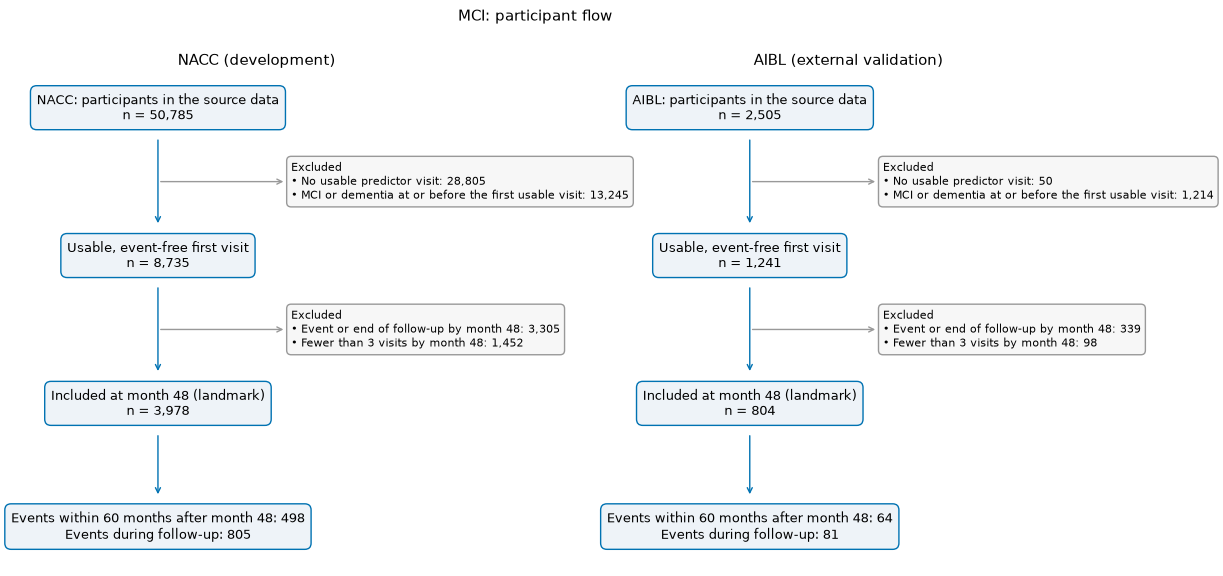

MCI: scoring Cox_ridge / baseline_visit
MCI: scoring Cox_ridge / 1_visit
MCI: scoring Cox_ridge / 2_visits
MCI: scoring Cox_ridge / 3_visits
MCI: scoring Cox_ridge / all_visits
MCI: scoring Cox_ridge / basic_only
MCI: scoring DeepSurv / baseline_visit
MCI: scoring DeepSurv / 1_visit
MCI: scoring DeepSurv / 2_visits
MCI: scoring DeepSurv / 3_visits
MCI: scoring DeepSurv / all_visits
MCI: scoring DynamicDeepHit / baseline_visit
MCI: scoring DynamicDeepHit / 1_visit
MCI: scoring DynamicDeepHit / 2_visits
MCI: scoring DynamicDeepHit / 3_visits
MCI: scoring DynamicDeepHit / all_visits
MCI NACC_internal: bootstrap 50/200
MCI NACC_internal: bootstrap 100/200
MCI NACC_internal: bootstrap 150/200
MCI NACC_internal: bootstrap 200/200
MCI AIBL_external: bootstrap 50/200
MCI AIBL_external: bootstrap 100/200
MCI AIBL_external: bootstrap 150/200
MCI AIBL_external: bootstrap 200/200


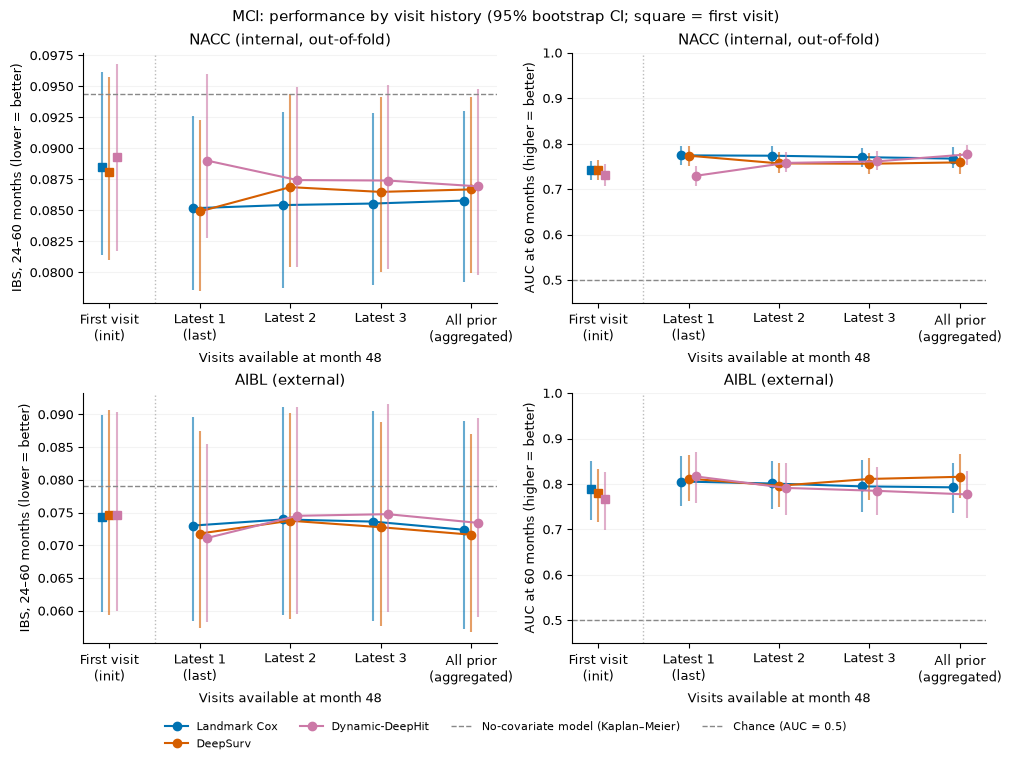

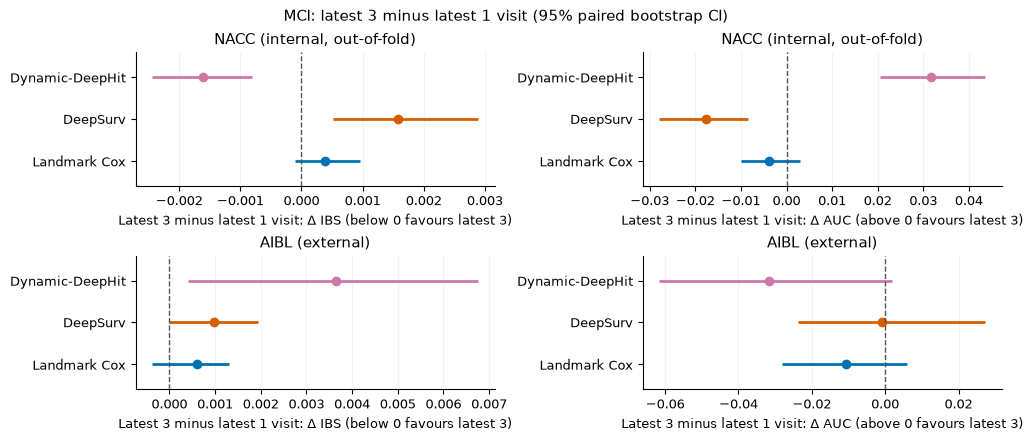

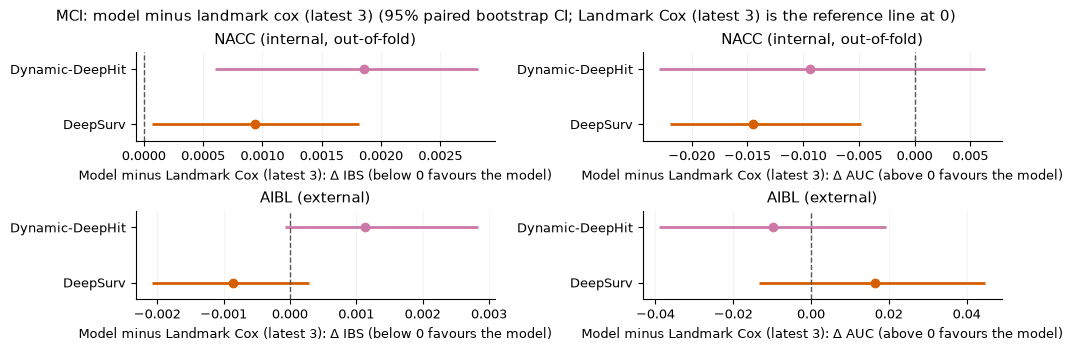

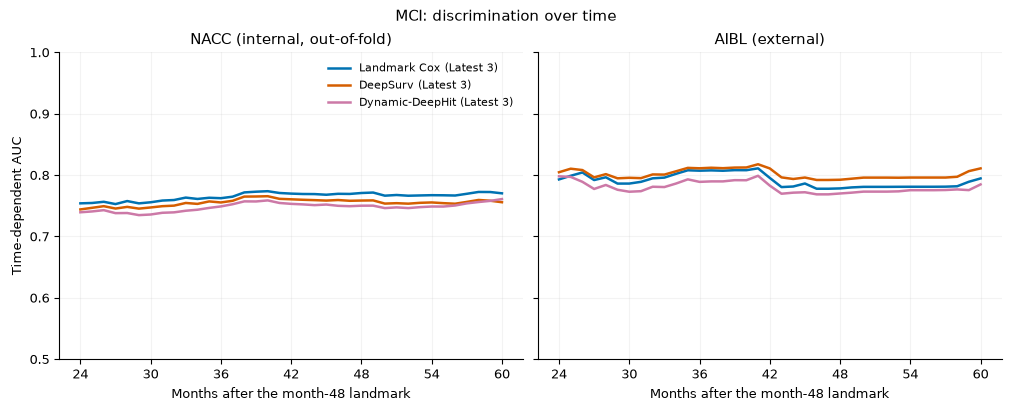

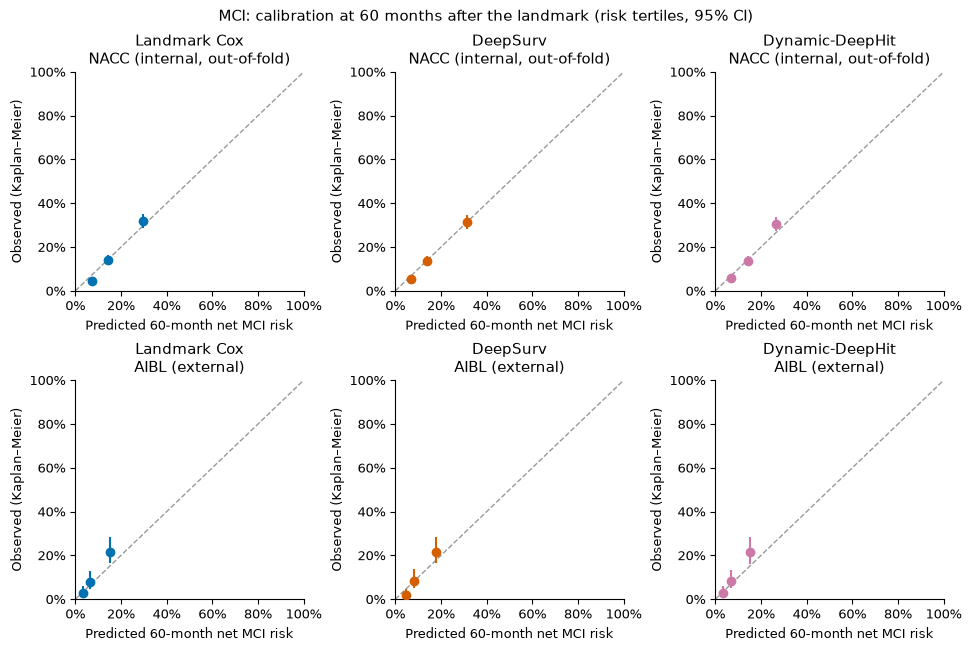

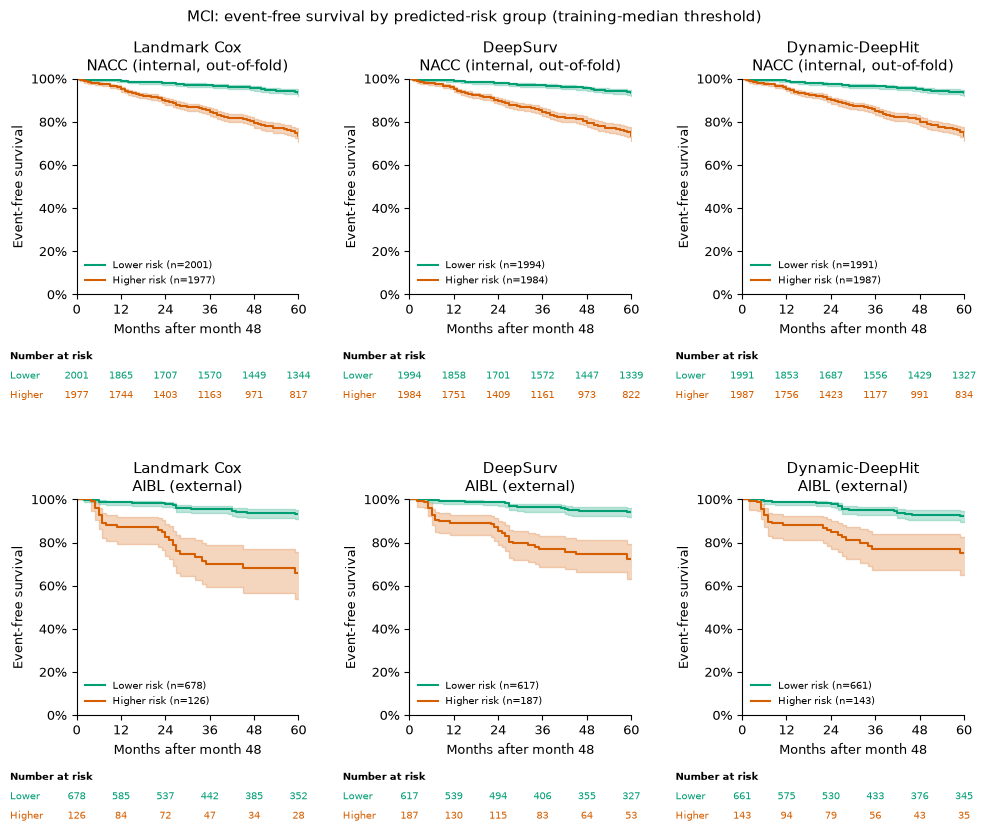

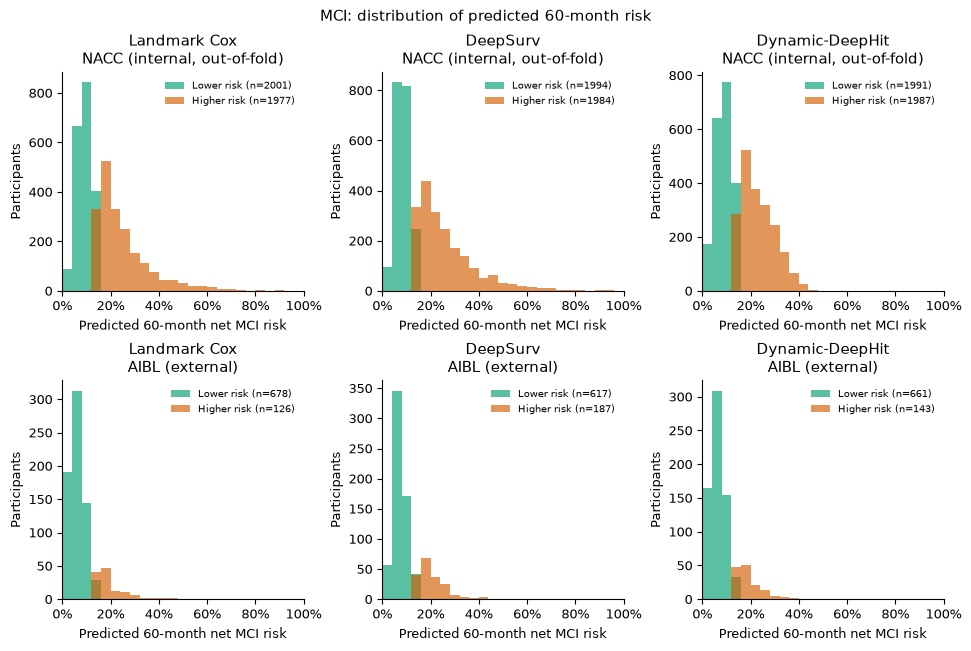

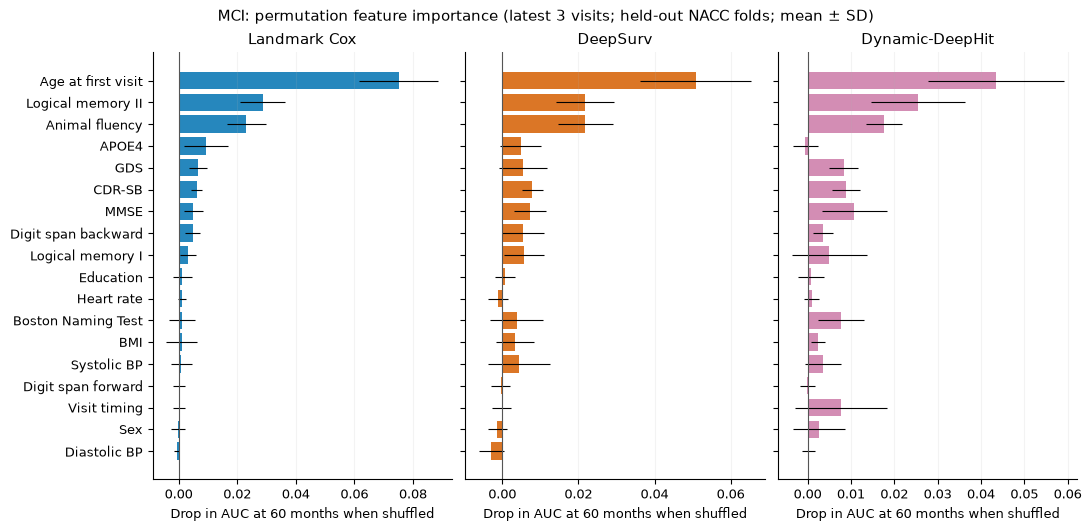

Models evaluated: ['Cox_ridge', 'DeepSurv', 'DynamicDeepHit']


,NACC (development),AIBL (external validation)
Characteristic,,
"Participants, n",3978,804
"Events within 24 months after month 48, n (%)",222 (5.6%),32 (4.0%)
"Events within 36 months after month 48, n (%)",310 (7.8%),52 (6.5%)
"Events within 60 months after month 48, n (%)",498 (12.5%),64 (8.0%)
"Events during follow-up (to 120 months), n (%)",805 (20.2%),81 (10.1%)
"Median follow-up after month 48, months (reverse Kaplan–Meier)",81.0,61.0
"Age at first visit, years, mean (SD)",71.8 (9.1),70.2 (6.5)
"Female, n (%)",2689 (67.6%),451 (56.1%)
"Education, years, mean (SD)",15.9 (2.9),12.7 (3.2)


,NACC,AIBL
Participants,,
source_participants,50785,2505
no_usable_visit,28805,50
prevalent,13245,1214
usable_baseline,8735,1241
event_or_censored_by_48,3305,339
fewer_than_3_visits,1452,98
included,3978,804
events_by_24m,222,32
events_by_36m,310,52


metric                                          n  events_by_60m  \
cohort        model          history                               
AIBL_external Cox_ridge      baseline_visit   804             64   
                             1_visit          804             64   
                             2_visits         804             64   
                             3_visits         804             64   
                             all_visits       804             64   
                             basic_only       804             64   
              DeepSurv       baseline_visit   804             64   
                             1_visit          804             64   
                             2_visits         804             64   
                             3_visits         804             64   
                             all_visits       804             64   
              DynamicDeepHit baseline_visit   804             64   
                             1_visit          804             64   
                             2_visits         804             64   
                             3_visits         804             64   
                             all_visits       804             64   
              Null_KM        no_covariates    804             64   
NACC_internal Cox_ridge      baseline_visit  3978            498   
                             1_visit         3978            498   
                             2_visits        3978            498   
                             3_visits        3978            498   
                             all_visits      3978            498   
                             basic_only      3978            498   
              DeepSurv       baseline_visit  3978            498   
                             1_visit         3978            498   
                             2_visits        3978            498   
                             3_visits        3978            498   
                             all_visits      3978            498   
              DynamicDeepHit baseline_visit  3978            498   
                             1_visit         3978            498   
                             2_visits        3978            498   
                             3_visits        3978            498   
                             all_visits      3978            498   
              Null_KM        no_covariates   3978            498   

metric                                                    IBS_24_60  \
cohort        model          history                                  
AIBL_external Cox_ridge      baseline_visit  0.074 (0.060 to 0.090)   
                             1_visit         0.073 (0.058 to 0.090)   
                             2_visits        0.074 (0.059 to 0.091)   
                             3_visits        0.074 (0.058 to 0.091)   
                             all_visits      0.072 (0.057 to 0.089)   
                             basic_only      0.074 (0.061 to 0.089)   
              DeepSurv       baseline_visit  0.075 (0.059 to 0.091)   
                             1_visit         0.072 (0.057 to 0.088)   
                             2_visits        0.074 (0.059 to 0.090)   
                             3_visits        0.073 (0.058 to 0.089)   
                             all_visits      0.072 (0.057 to 0.087)   
              DynamicDeepHit baseline_visit  0.075 (0.060 to 0.090)   
                             1_visit         0.071 (0.058 to 0.086)   
                             2_visits        0.075 (0.060 to 0.091)   
                             3_visits        0.075 (0.060 to 0.092)   
                             all_visits      0.073 (0.059 to 0.089)   
              Null_KM        no_covariates   0.079 (0.065 to 0.094)   
NACC_internal Cox_ridge      baseline_visit  0.089 (0.081 to 0.096)   
                             1_visit         0.085 (0.079 to 0.093)   
                             2_visits        0.085 (0.079 to

In [4]:
mci = ev.run("MCI", RUN_MODE, MODELS)
print("Models evaluated:", mci.models)
display(mci.table1)   # Table 1: landmark cohort characteristics
display(mci.flow)     # Table S1: participant flow
display(mci.table2)   # Table 2: performance by model and visit history

In [5]:
display(mci.table3)

metric                                                                                                 IBS_24_60  \
cohort        contrast                                  model          history                                     
AIBL_external history minus latest 1 visit (same model) Cox_ridge      baseline_visit    0.001 (-0.000 to 0.003)   
                                                                       2_visits           0.001 (0.000 to 0.002)   
                                                                       3_visits          0.001 (-0.000 to 0.001)   
                                                                       all_visits       -0.001 (-0.002 to 0.000)   
                                                        DeepSurv       baseline_visit     0.003 (0.001 to 0.005)   
                                                                       2_visits           0.002 (0.001 to 0.003)   
                                                                       3_visits          0.001 (-0.000 to 0.002)   
                                                                       all_visits       -0.000 (-0.002 to 0.001)   
                                                        DynamicDeepHit baseline_visit     0.004 (0.000 to 0.006)   
                                                                       2_visits           0.003 (0.000 to 0.007)   
                                                                       3_visits           0.004 (0.000 to 0.007)   
                                                                       all_visits        0.002 (-0.000 to 0.005)   
              model minus Landmark Cox (latest 3)       DeepSurv       3_visits         -0.001 (-0.002 to 0.000)   
                                                        DynamicDeepHit 3_visits          0.001 (-0.000 to 0.003)   
NACC_internal history minus latest 1 visit (same model) Cox_ridge      baseline_visit     0.003 (0.002 to 0.004)   
                                                                       2_visits          0.000 (-0.000 to 0.001)   
                                                                       3_visits          0.000 (-0.000 to 0.001)   
                                                                       all_visits        0.001 (-0.000 to 0.002)   
                                                        DeepSurv       baseline_visit     0.003 (0.002 to 0.004)   
                                                                       2_visits           0.002 (0.001 to 0.003)   
                                                                       3_visits           0.002 (0.001 to 0.003)   
                                                                       all_visits         0.002 (0.001 to 0.003)   
                                                        DynamicDeepHit baseline_visit    0.000 (-0.001 to 0.001)   
                                                                       2_visits        -0.002 (-0.002 to -0.001)   
                                                                       3_visits        -0.002 (-0.002 to -0.001)   
                                                                       all_visits      -0.002 (-0.003 to -0.001)   
              model minus Landmark Cox (latest 3)       DeepSurv       3_visits           0.001 (0.000 to 0.002)   
                                                        DynamicDeepHit 3_visits           0.002 (0.001 to 0.003)   

metric                                                                                         IBS_change_pct  \
cohort        contrast                                  model          history                                  
AIBL_external history minus latest 1 visit (same model) Cox_ridge      baseline_visit  +1.8% (-0.3% to +4.2%)   
                                                                       2_visits        +1.3% (+0.5% to +2.1%)   
                                                                   